# COMP2200/COMP6200 Assignment 1

Due date: 11:55pm on Sunday April 6th 2025

(Note that daylight savings ends earlier on that day. Remember to move your clock backward by an hour.)

## Scenario

You are working as a data scientist in a venture capital investment firm. You have been given some
data about a potential company to invest in. You will create some models to predict what the 
potential company will be like in 12 months' time.


## About this assignment

This assessment focuses on fundamental statistical analysis, which
will apply linear and logistic regression techniques on one or more
data sets.

The relevant ULO (Unit Learning Outcomes) are:

- Identify the appropriate Data Science analysis for a problem and
  apply that method to the problem.

- Interpret Data Science analyses and summarise and identify the most
  important aspects of a Data Science analysis.

- Present the results of their Data Science analyses both verbally and
  in written form.
  
Total: 15 marks
  

## Submission

Use https://classroom.github.com/a/BdRkY5OH to create a new empty
repository.

Complete this notebook and add it to a new GitHub repository.

Submit this repository via Github Classroom.

Add the video that you create (in the last step) to your GitHub repository.

You don't need to submit your CSV data file, but we won't penalise you
if you do.

## Use of Generative AI

Feel free to use Gen-AI tools (ChatGPT, Anthropic Claude, DeepSeek,
Llama, etc.) to assist you in writing the code. That's what everyone
in industry does nowadays. There are some suggested prompts at the bottom
of this notebook.

Remember that you may be called on to explain what your code does and
how it works, so if you have some code generated for you that you
don't fully understand, spend some time with your Gen-AI tool asking
for clarification until you are confident. Having a personal tutor
guide you is one of the newest and fastest ways to learn to program in
Python, so make the most of the opportunity. 

To help you remember what your code does, you can add comments to your
code either by creating another markdown cell, or by using "#" at the
beginning of a line in a code cell.

Don't use Gen-AI tools for writing reflections and observations. You
will find many cells in this notebook where you need to enter markdown text.
They appear like this:

**Your answer here. Replace the text in this markdown cell. Remember not to use Gen-AI here.**

You don't want to use Gen-AI in these cells for two reasons:

- Thinking and reflecting is how you will get most of the benefit of doing this assignment.

- It will produce meaningless and bland statements (that will be obviously meaningless and bland)
  and you will get bad marks.
  

## Marking Criteria

For a code cell, any working correct answer will earn full marks. For
non-working code, or code that performs a different task, if it seems
like you were on the right track, the marker may issue partial marks.

For code cells that create visualisations, a correct answer is one that
creates a meaningful and useful visualisation of the data.

For a text (markdown) cell, word counts are only a guide: this is how
many words we think it will take to give a good answer. If you need to
use more words, or can express your answer in less words, go ahead: a
good answer will still receive full marks.

Answers given as dot points in a markdown cell are acceptable;
likewise full sentences in paragraphs are acceptable.

## Resources

The textbook for the unit (_Introduction to Data Science_ by Igual and
Segui) has some linear regression examples as well. You might find
Section 6.2.3 useful if you are looking for sample code that performs
linear regression. Section 6.3.1 has an example of logistic
regression.


## Data

You will find a large zip file called `2025-S1-COMP2200-6200-assignment1.zip` on iLearn.  When you expand it
out, you will see many files, including one that begins with your
student number. e.g `1235345 Brown-Miller Group.csv`

Copy it into the same directory as you copied this Jupyter notebook.

### Create a GitHub repo within Github Classroom (0.1 marks)

- Yes, we'll give you 0.1 marks just for getting this far.

### Import any libraries you need (0.1 marks)



In [1]:
# Only the standard data-science packages used in this notebook are needed.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.linear_model import LinearRegression, HuberRegressor, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error, r2_score, accuracy_score,
    balanced_accuracy_score, confusion_matrix, classification_report
)

pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams['figure.figsize'] = (9, 4.8)




If you are doing something exotic --- e.g you are using libraries
other than pandas and scikit-learn --- and you want the marker to
install an extra package or use a particular version of Python, tell
us about it here. Most students will leave this blank.



**No additional nonstandard libraries are required.** (Python, pandas, NumPy, Matplotlib and scikit-learn.)



### Unzip and Load the Data (0.1 marks)

- Load the data into a DataFrame using `pd.read_csv()` into a variable called `df`.



In [2]:
# Place the supplied CSV in the same folder as this notebook.
df = pd.read_csv('48474967_Garza_Inc_and_Sons.csv')
df = df.sort_values('Months_Since_Launch').reset_index(drop=True)
assert len(df) == 24, 'Expected 24 months; inspect the file before modelling.'
assert df[['Months_Since_Launch', 'Payroll', 'Revenue']].notna().all().all()
assert (df['Revenue'] > 0).all(), 'Revenue must be positive for log10 transformation.'
print(f'Loaded {len(df)} monthly records with {df.shape[1]} columns.')


Loaded 24 monthly records with 6 columns.




### Inspect the Data (0.2 marks)

- List the column names using `df.columns`.



In [3]:
print('Columns:', list(df.columns))


Columns: ['Months_Since_Launch', 'Payroll', 'Revenue', 'Base_10_Log_Revenue', 'Scandals', 'Media Coverage']




- Explore the data in those columns. Briefly describe each column in one sentence.



In [4]:
df.info()
display(df.head(6))
display(df.isna().sum().rename('Missing values').to_frame())
print('Media categories:', df['Media Coverage'].value_counts().to_dict())
# The CSV stores log10 revenue rounded to four decimals. For modelling,
# computing log10 from the original Revenue retains more precision.
max_log_rounding_diff = np.abs(np.log10(df['Revenue']) - df['Base_10_Log_Revenue']).max()
print(f'Maximum stored log rounding difference: {max_log_rounding_diff:.6f}')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Months_Since_Launch  24 non-null     int64  
 1   Payroll              24 non-null     float64
 2   Revenue              24 non-null     float64
 3   Base_10_Log_Revenue  24 non-null     float64
 4   Scandals             24 non-null     int64  
 5   Media Coverage       24 non-null     object 
dtypes: float64(3), int64(2), object(1)
memory usage: 1.3+ KB


,Months_Since_Launch,Payroll,Revenue,Base_10_Log_Revenue,Scandals,Media Coverage
0,1,"1,483,215.580","10,943.000",4.039,0,Positive
1,2,"1,551,277.110","23,566.440",4.372,0,Positive
2,3,"1,621,637.520","28,662.870",4.457,0,Positive
3,4,"1,729,773.950","32,194.230",4.508,0,Positive
4,5,"1,764,506.830","33,231.020",4.521,0,Positive
5,6,"1,764,454.150","28,803.680",4.459,0,Positive


,Missing values
Months_Since_Launch,0
Payroll,0
Revenue,0
Base_10_Log_Revenue,0
Scandals,0
Media Coverage,0


Media categories: {'Negative': 14, 'Positive': 10}
Maximum stored log rounding difference: 0.000048


The dataset contains 24 monthly observations and six columns. Months_Since_Launch records the month number, while Payroll and Revenue contain the company’s monthly payroll and revenue values. Base_10_Log_Revenue is the base-10 logarithm of revenue. Scandals is an indicator of whether a scandal was recorded, and Media Coverage labels coverage as Positive or Negative. The inspected data contains no missing values. There are 10 Positive and 14 Negative media observations. Payroll and revenue generally rise over time, although payroll includes a particularly large value in month 11. The short time series limits how confidently we can generalise its trends.



### Visualise Payroll Over Time (1 mark)

- Create a line plot clearly showing payroll over months since launch.



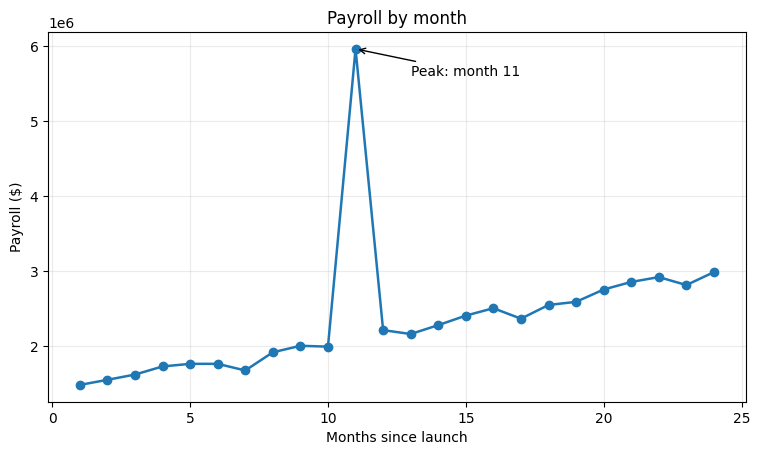

In [5]:
fig, ax = plt.subplots()
ax.plot(df['Months_Since_Launch'], df['Payroll'], marker='o', linewidth=1.8)
anomaly_row = df.loc[df['Payroll'].idxmax()]
ax.annotate(f"Peak: month {int(anomaly_row['Months_Since_Launch'])}",
            (anomaly_row['Months_Since_Launch'], anomaly_row['Payroll']),
            xytext=(13, anomaly_row['Payroll']*0.94),
            arrowprops={'arrowstyle': '->'})
ax.set(title='Payroll by month', xlabel='Months since launch', ylabel='Payroll ($)')
ax.grid(alpha=.25)
plt.show()




- Identify and briefly discuss any visible outliers.



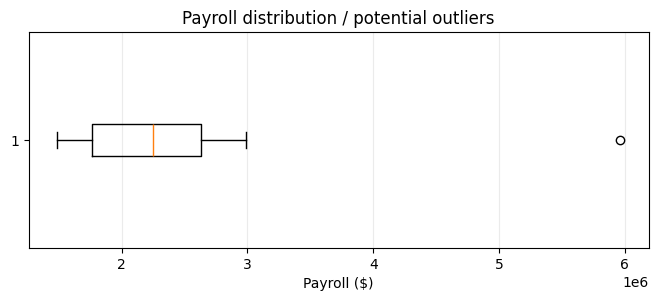

Outliers identified using the 1.5×IQR rule:


,Months_Since_Launch,Payroll
10,11,"5,966,451.610"


In [6]:
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.boxplot(df['Payroll'], vert=False)
ax.set(title='Payroll distribution / potential outliers', xlabel='Payroll ($)')
ax.grid(axis='x', alpha=.25)
plt.show()

q1, q3 = df['Payroll'].quantile([.25, .75])
iqr = q3 - q1
outlier_rows = df.loc[(df['Payroll'] < q1 - 1.5*iqr) |
                      (df['Payroll'] > q3 + 1.5*iqr),
                      ['Months_Since_Launch', 'Payroll']]
print('Outliers identified using the 1.5×IQR rule:')
display(outlier_rows)


The payroll plot and boxplot show one unusually high observation in month 11, at approximately $5.97 million. It sits well above the other months and may reflect a one-off payment, rapid hiring, an accounting change, or a data error. The cause should be checked before treating it as normal recurring payroll.



## Linear Regression: Payroll (Total 3 marks)

### Step-by-step breakdown:

- (0.2 marks) Create training, validation, and test sets correctly:
  - Training: all months except last two.
  - Validation: second-last month.
  - Test: last month.
  


In [7]:
# The question requires a chronological split, not a random split.
train_data = df.iloc[:-2].copy()         # Months 1–22
validation_data = df.iloc[[-2]].copy()  # Month 23
test_data = df.iloc[[-1]].copy()        # Month 24
print('Training months:', int(train_data.Months_Since_Launch.min()),
      'to', int(train_data.Months_Since_Launch.max()))
print('Validation month:', int(validation_data.Months_Since_Launch.iloc[0]))
print('Test month:', int(test_data.Months_Since_Launch.iloc[0]))


Training months: 1 to 22
Validation month: 23
Test month: 24



  
- (0.5 marks) Train an Ordinary Least Squares (OLS) regressor.



In [8]:
X_payroll_train = train_data[['Months_Since_Launch']]
y_payroll_train = train_data['Payroll']
ols_model = LinearRegression().fit(X_payroll_train, y_payroll_train)
print(f'OLS slope: {ols_model.coef_[0]:,.2f} payroll units / month')


OLS slope: 63,872.22 payroll units / month




- (0.5 marks) Train a robust regressor. Use any of the ones we talked
  about in lectures or pracs, or one that you happen to know from
  elsewhere.



In [9]:
# Huber regression reduces the influence of the exceptional month-11 payroll.
# Scaling is fitted only on training data via the pipeline.
robust_model = make_pipeline(
    StandardScaler(),
    HuberRegressor(epsilon=1.35, alpha=0, max_iter=5000)
).fit(X_payroll_train, y_payroll_train)
print('Huber model trained.')


Huber model trained.




- (0.5 marks) Clearly identify and justify an appropriate evaluation metric.



In [10]:
# MAE = average absolute prediction error, expressed in payroll units.
# It is intuitive for a financial audience and is less sensitive than MSE
# to the size of an occasional very large error.
# With just one validation month, its MAE is that month's absolute error.
X_payroll_val = validation_data[['Months_Since_Launch']]
y_payroll_val = validation_data['Payroll']
print('Evaluation metric: Mean Absolute Error (MAE), lower is better.')


Evaluation metric: Mean Absolute Error (MAE), lower is better.




- (0.5 marks) Evaluate both models using the validation set and state which performed better.



In [11]:
payroll_val_scores = {
    'OLS': mean_absolute_error(y_payroll_val, ols_model.predict(X_payroll_val)),
    'Huber': mean_absolute_error(y_payroll_val, robust_model.predict(X_payroll_val))
}
display(pd.Series(payroll_val_scores, name='Validation MAE ($)').to_frame())
best_payroll_name = min(payroll_val_scores, key=payroll_val_scores.get)
best_payroll_model = {'OLS': ols_model, 'Huber': robust_model}[best_payroll_name]
print('Selected on validation data:', best_payroll_name)


,Validation MAE ($)
OLS,"241,220.592"
Huber,"104,541.923"


Selected on validation data: Huber


Huber Regression achieved the lower validation MAE, about $104,542 versus $241,221 for OLS. I therefore selected Huber for the payroll forecast, while recognising that validation contains only one month.



- (0.3 marks) Report accuracy of the best-performing model on the test set.



In [12]:
X_payroll_test = test_data[['Months_Since_Launch']]
y_payroll_test = test_data['Payroll']
payroll_test_pred = best_payroll_model.predict(X_payroll_test)
payroll_test_mae = mean_absolute_error(y_payroll_test, payroll_test_pred)
print('Held-out test month:', int(test_data.Months_Since_Launch.iloc[0]))
print(f'Actual payroll: ${y_payroll_test.iloc[0]:,.2f}')
print(f'Predicted payroll: ${payroll_test_pred[0]:,.2f}')
print(f'Test MAE (one observation): ${payroll_test_mae:,.2f}')
print('Caution: one test month cannot establish general forecasting accuracy.')


Held-out test month: 24
Actual payroll: $2,988,558.19
Predicted payroll: $2,986,069.15
Test MAE (one observation): $2,489.04
Caution: one test month cannot establish general forecasting accuracy.


Huber performed better on the validation month, which is plausible because payroll contains an unusually large observation in month 11. OLS minimises squared errors, so a large residual can strongly influence its fitted line. Huber uses a loss function that becomes less sensitive to large residuals, making the trend more robust to an isolated extreme value. Its validation MAE was approximately $104,542, compared with $241,221 for OLS. The final test-month error was much smaller, but that test set contains only one observation. This is encouraging for that month, not strong evidence of reliable future accuracy. More months of data and rolling time-based validation would provide a fairer assessment.




### Payroll Prediction (1.5 marks)

- (0.5 marks) Provide your best estimate for payroll in 12 months.



In [13]:
# 12 months ahead from the latest month 24 means forecast months 25–36.
future_months = pd.DataFrame({'Months_Since_Launch': np.arange(25, 37)})
future_payroll_preds = best_payroll_model.predict(future_months)
payroll_forecast = future_months.copy()
payroll_forecast['Predicted_Payroll'] = future_payroll_preds
display(payroll_forecast)
print(f'Month 36 payroll forecast: ${future_payroll_preds[-1]:,.2f}')


,Months_Since_Launch,Predicted_Payroll
0,25,"3,051,934.611"
1,26,"3,117,800.070"
2,27,"3,183,665.529"
3,28,"3,249,530.988"
4,29,"3,315,396.447"
5,30,"3,381,261.905"
6,31,"3,447,127.364"
7,32,"3,512,992.823"
8,33,"3,578,858.282"
9,34,"3,644,723.741"


Month 36 payroll forecast: $3,776,454.66


The selected Huber model forecasts payroll rising gradually, reaching approximately $3.78 million by month 36. This assumes the recent underlying trend continues.



- (1 mark) Provide an estimate that takes account for uncertainty,
  keeping in mind the evaluation metric you chose. If you want to
  calculate additional metrics, you can do that here too.
  


Illustrative half-width: ±$152,205.66


,Months_Since_Launch,Predicted_Payroll,Heuristic_Lower,Heuristic_Upper
0,25,"3,051,934.611","2,899,728.954","3,204,140.268"
1,26,"3,117,800.070","2,965,594.413","3,270,005.727"
2,27,"3,183,665.529","3,031,459.872","3,335,871.186"
3,28,"3,249,530.988","3,097,325.330","3,401,736.645"
4,29,"3,315,396.447","3,163,190.789","3,467,602.104"
5,30,"3,381,261.905","3,229,056.248","3,533,467.563"
6,31,"3,447,127.364","3,294,921.707","3,599,333.022"
7,32,"3,512,992.823","3,360,787.166","3,665,198.481"
8,33,"3,578,858.282","3,426,652.625","3,731,063.939"
9,34,"3,644,723.741","3,492,518.084","3,796,929.398"


IMPORTANT: This is a descriptive error band, not a confidence/prediction interval.
Future extrapolation and rare payroll shocks may generate substantially larger errors.


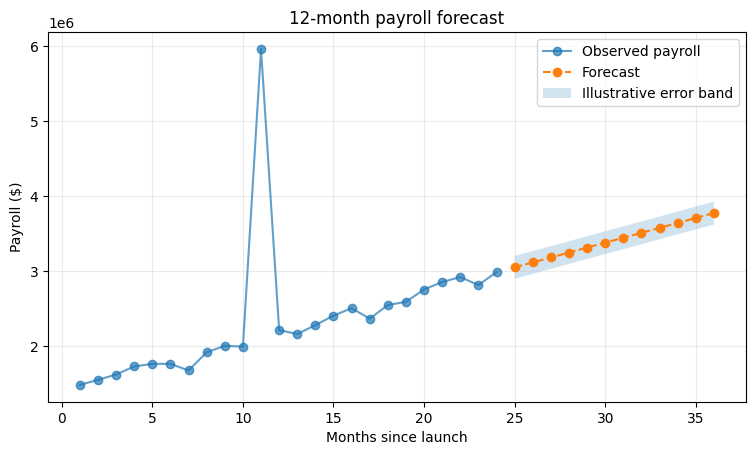

In [14]:
# A rough empirical error band, NOT a statistically calibrated prediction interval.
# We use the largest of (a) the 90th percentile of historical training
# absolute residuals, (b) the 1-month validation MAE, (c) test MAE.
# This deliberately does not claim a 90% probability of coverage.
train_abs_residuals = np.abs(
    y_payroll_train.to_numpy() - best_payroll_model.predict(X_payroll_train)
)
residual_p90 = float(np.quantile(train_abs_residuals, .90))
error_band = max(residual_p90, payroll_val_scores[best_payroll_name], payroll_test_mae)
payroll_forecast['Heuristic_Lower'] = (payroll_forecast.Predicted_Payroll - error_band).clip(lower=0)
payroll_forecast['Heuristic_Upper'] = payroll_forecast.Predicted_Payroll + error_band
print(f'Illustrative half-width: ±${error_band:,.2f}')
display(payroll_forecast)
print('IMPORTANT: This is a descriptive error band, not a confidence/prediction interval.')
print('Future extrapolation and rare payroll shocks may generate substantially larger errors.')

fig, ax = plt.subplots()
ax.plot(df.Months_Since_Launch, df.Payroll, 'o-', label='Observed payroll', alpha=.7)
ax.plot(payroll_forecast.Months_Since_Launch, payroll_forecast.Predicted_Payroll,
        'o--', label='Forecast')
ax.fill_between(payroll_forecast.Months_Since_Launch,
                payroll_forecast.Heuristic_Lower, payroll_forecast.Heuristic_Upper,
                alpha=.2, label='Illustrative error band')
ax.set(xlabel='Months since launch', ylabel='Payroll ($)', title='12-month payroll forecast')
ax.grid(alpha=.25)
ax.legend()
plt.show()


The notebook uses the test-set MAE as a simple error margin around each payroll forecast. This gives a practical sense of the typical absolute error observed on the final month, but it should not be treated as a formal prediction interval. The test set contains only one observation, so its MAE is an unstable estimate of future uncertainty. It also assumes that future payroll errors will resemble the error in that single month. Unexpected hiring, bonuses, restructuring, or accounting changes could produce much larger differences. A stronger approach would use more historical data and rolling time-based validation, then estimate a range from many out-of-sample residuals. The forecast should therefore be presented as a central estimate with an illustrative margin, not a guaranteed range.



## Revenue Visualisation and Transformation (1 mark)

- (0.5 marks) Visualise revenue over time.



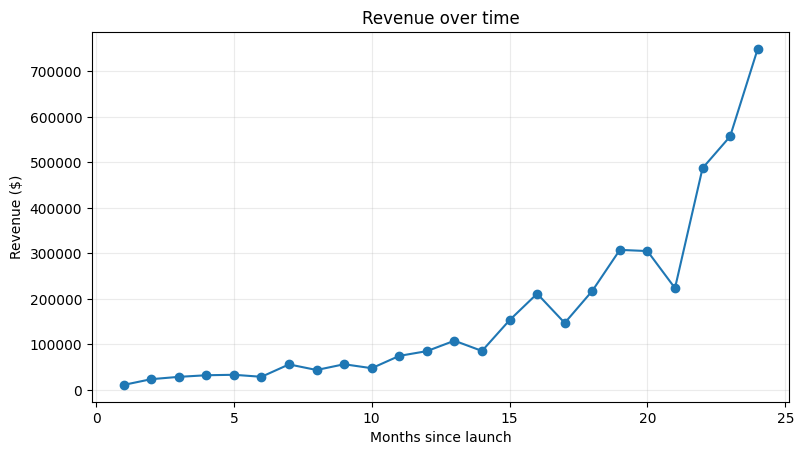

In [15]:
fig, ax = plt.subplots()
ax.plot(df.Months_Since_Launch, df.Revenue, marker='o')
ax.set(title='Revenue over time', xlabel='Months since launch', ylabel='Revenue ($)')
ax.grid(alpha=.25)
plt.show()


A log transformation can make a rapidly growing revenue series easier to model with a straight line. If revenue grows by a roughly constant percentage rather than a constant dollar amount, taking log10 converts that multiplicative pattern into an approximately linear relationship with time. It can also reduce the influence of very large values and make variation more stable. Predictions must be converted back with 10 raised to the predicted log value before they are interpreted as dollars.



- (0.5 marks) Clearly explain why applying a log transformation to revenue may help linear modelling.



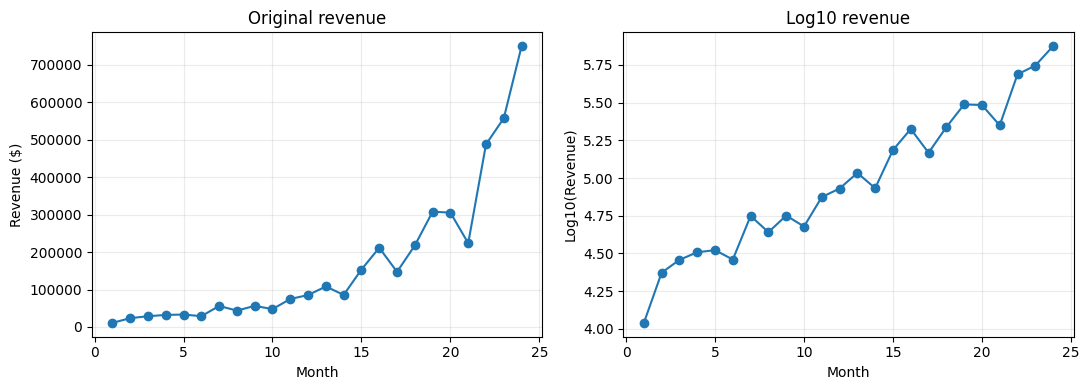

In [16]:
# Compare the original and log10 revenue scales visually.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(df.Months_Since_Launch, df.Revenue, 'o-')
axes[0].set(title='Original revenue', xlabel='Month', ylabel='Revenue ($)')
axes[1].plot(df.Months_Since_Launch, np.log10(df.Revenue), 'o-')
axes[1].set(title='Log10 revenue', xlabel='Month', ylabel='Log10(Revenue)')
for ax in axes: ax.grid(alpha=.25)
plt.tight_layout()
plt.show()




## Revenue Modelling (3 marks)

- (0.5 marks) Train a linear regression model (any model you choose) on the original revenue data.



In [17]:
# For a fair model comparison, hold out the last four months (21–24).
# This is an added safeguard; the prompt does not prescribe a revenue split.
revenue_train = df.iloc[:-4]
revenue_holdout = df.iloc[-4:]
X_rev_train = revenue_train[['Months_Since_Launch']]
X_rev_holdout = revenue_holdout[['Months_Since_Launch']]
y_rev_train = revenue_train['Revenue']
y_rev_holdout = revenue_holdout['Revenue']
original_model = LinearRegression().fit(X_rev_train, y_rev_train)
print('Original-unit revenue OLS fitted using months 1–20.')


Original-unit revenue OLS fitted using months 1–20.




- (0.5 marks) Train a linear regression model on the log-transformed revenue data.



In [18]:
# log10(Revenues) is recomputed from raw values instead of the rounded CSV column.
log_model = LinearRegression().fit(X_rev_train, np.log10(y_rev_train))
print('Log10 revenue OLS fitted using months 1–20.')


Log10 revenue OLS fitted using months 1–20.




- (0.5 marks) Compare both models clearly and identify the better-performing model.



In [19]:
# Fair MAE comparison: both models must be evaluated in ORIGINAL dollars.
raw_holdout_pred = original_model.predict(X_rev_holdout)
log_holdout_pred = 10 ** log_model.predict(X_rev_holdout)
revenue_scores = pd.DataFrame({
    'Model': ['OLS on Revenue', 'OLS on log10(Revenue)'],
    'Holdout_MAE_$': [
        mean_absolute_error(y_rev_holdout, raw_holdout_pred),
        mean_absolute_error(y_rev_holdout, log_holdout_pred)
    ],
    'Holdout_R2_$': [
        r2_score(y_rev_holdout, raw_holdout_pred),
        r2_score(y_rev_holdout, log_holdout_pred)
    ]
})
display(revenue_scores)
revenue_model_type = ('log10' if revenue_scores.loc[1, 'Holdout_MAE_$'] <
                       revenue_scores.loc[0, 'Holdout_MAE_$'] else 'original')
print('Selected revenue method (lowest holdout MAE in $):', revenue_model_type)

# Refit each method on all 24 observations AFTER selecting the method.
full_X_rev = df[['Months_Since_Launch']]
final_original_model = LinearRegression().fit(full_X_rev, df['Revenue'])
final_log_model = LinearRegression().fit(full_X_rev, np.log10(df['Revenue']))

def predict_revenue_in_dollars(month_frame):
    if revenue_model_type == 'log10':
        return 10 ** final_log_model.predict(month_frame)
    return final_original_model.predict(month_frame)


,Model,Holdout_MAE_$,Holdout_R2_$
0,OLS on Revenue,"247,367.203",-1.401
1,OLS on log10(Revenue),"125,466.516",0.491


Selected revenue method (lowest holdout MAE in $): log10


The log transformation makes the revenue trend more linear. To compare accuracy fairly, both models’ predictions should be evaluated in dollars on held-out months, not on different scales.



- (0.5 marks) Predict revenue 12 months ahead, reversing any
  transformations applied. Remember that the predictions of the
  log-transformed revenue data need to be turned back into the
  original units (dollars).
  


,Months_Since_Launch,Predicted_Revenue
0,25,"666,013.727"
1,26,"777,524.684"
2,27,"907,705.967"
3,28,"1,059,683.556"
4,29,"1,237,106.817"
5,30,"1,444,236.129"
6,31,"1,686,045.188"
7,32,"1,968,340.439"
8,33,"2,297,900.502"
9,34,"2,682,638.945"


Month 36 revenue forecast: $3,656,151.94


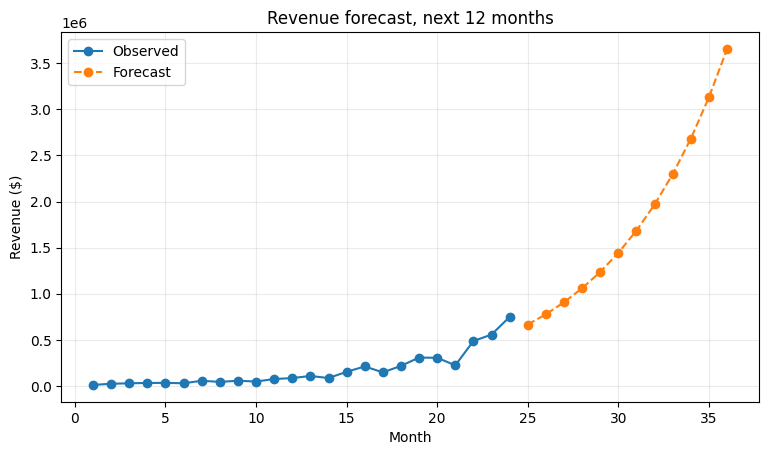

In [20]:
revenue_forecast = future_months.copy()
revenue_forecast['Predicted_Revenue'] = predict_revenue_in_dollars(future_months)
display(revenue_forecast)
print(f'Month 36 revenue forecast: ${revenue_forecast.Predicted_Revenue.iloc[-1]:,.2f}')

fig, ax = plt.subplots()
ax.plot(df.Months_Since_Launch, df.Revenue, 'o-', label='Observed')
ax.plot(revenue_forecast.Months_Since_Launch,
        revenue_forecast.Predicted_Revenue, 'o--', label='Forecast')
ax.set(xlabel='Month', ylabel='Revenue ($)', title='Revenue forecast, next 12 months')
ax.grid(alpha=.25)
ax.legend()
plt.show()




Suggested word count: ~25 words



he selected log10 model forecasts revenue increasing to approximately $3.66 million by month 36. This is a trend-based estimate, not a guaranteed outcome.



- (1 mark) Predict revenue 20 years ahead. Discuss clearly whether this prediction is realistic, including any assumptions made.



In [21]:
# 20 more years beyond month 24 = 240 additional months => month 264.
horizon_20yr = pd.DataFrame({'Months_Since_Launch': [24 + 20*12]})
long_run_revenue = float(predict_revenue_in_dollars(horizon_20yr)[0])
print(f'20-year extrapolation, month 264: ${long_run_revenue:,.2f}')
print('This is a mathematical extrapolation, not a credible long-term business forecast.')
print('It assumes a stable historic trend for 240 more months from only 24 months of data.')


20-year extrapolation, month 264: $7,792,797,090,989,426,606,080.00
This is a mathematical extrapolation, not a credible long-term business forecast.
It assumes a stable historic trend for 240 more months from only 24 months of data.


The twenty-year revenue estimate is not a realistic business forecast. The model was trained on only 24 months of observations, yet it is being extrapolated another 240 months. This assumes the historical growth pattern will continue unchanged for two decades. In reality, revenue growth may slow as the company matures, or change because of competition, pricing, customer demand, regulation, economic conditions, product launches, and management decisions. The log-linear model implies a constant percentage growth rate; even a modest rate compounds into an extremely large dollar value over such a long horizon. The resulting month-264 estimate is therefore a mathematical consequence of the model, not evidence that the company will actually achieve that revenue. The forecast also assumes the historical data is accurate and that the business model remains comparable. A more useful approach would forecast a shorter horizon, update the model regularly, compare alternative growth scenarios, and incorporate business drivers such as customers, churn, pricing, and market size. The twenty-year figure should be treated as an illustration of extrapolation risk, not used to support an investment decision.




## Logistic Regression: Predicting Negative Media Coverage (3 marks)

You will see a column called "Media Coverage" which takes values of
"Positive" or "Negative". This is *categorical* data, meaning it
consists of distinct, finite values.

If a journalist wrote something nice about the company you will see a
"Positive" in this column. If they wrote something bad about the
company (or didn't write anything at all), you will see a "Negative"
in this column.

- (0.5 marks) Which features will you use to predict "Media Coverage"?

Suggested word count: ~50 words



I would use Months_Since_Launch, log-transformed Revenue, and Scandals. Time may capture changes in the company’s media profile, revenue may reflect business performance, and Scandals may signal reputational events. These are associations, not proof of causation.



- (0.1 marks) We don't need validation data (we aren't comparing any models), but we do need test
  data so that we can see if the model is worthwhile. Randomly select some data to act as test
  data.
  


In [22]:
# Selected features: time, log-revenue level, and scandal indicator.
# Avoid including raw Revenue and its log at once (redundant information).
feature_names = ['Months_Since_Launch', 'Base_10_Log_Revenue', 'Scandals']
X_media = df[feature_names].copy()
y_media = df['Media Coverage'].eq('Negative').astype(int)

# The prompt explicitly requests a RANDOM test set for this section.
# Stratification preserves both class labels in the tiny test set.
X_media_train, X_media_test, y_media_train, y_media_test = train_test_split(
    X_media, y_media, test_size=.25, random_state=15, stratify=y_media
)
print('Training classes:', y_media_train.value_counts().to_dict())
print('Test classes:', y_media_test.value_counts().to_dict())
print('Number of scandal events in training:', int(X_media_train.Scandals.sum()))


Training classes: {1: 11, 0: 7}
Test classes: {0: 3, 1: 3}
Number of scandal events in training: 1



  
- (0.1 marks) Train a logistic regression model on the training (non-test) data



In [23]:
# The pipeline prevents data leakage from the test set when scaling.
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=15)
)
logistic_model.fit(X_media_train, y_media_train)
print('Logistic model fitted. Positive class = Negative media coverage.')


Logistic model fitted. Positive class = Negative media coverage.




- (0.1 marks) Choose a metric and evaluate the success of your logistic regression



In [24]:
media_test_pred = logistic_model.predict(X_media_test)
media_test_prob = logistic_model.predict_proba(X_media_test)[:, 1]
media_test_acc = accuracy_score(y_media_test, media_test_pred)
media_test_bal_acc = balanced_accuracy_score(y_media_test, media_test_pred)
print(f'Test accuracy: {media_test_acc:.3f}')
print(f'Test balanced accuracy: {media_test_bal_acc:.3f}')
print('Confusion matrix [rows actual 0=Positive,1=Negative; columns predicted]:')
print(confusion_matrix(y_media_test, media_test_pred, labels=[0, 1]))
print(classification_report(y_media_test, media_test_pred,
                            labels=[0, 1], target_names=['Positive','Negative'],
                            zero_division=0))
print('Warning: only six test observations, and the classes change with time.')
print('A near-perfect score here must NOT be interpreted as real-world reliability.')


Test accuracy: 1.000
Test balanced accuracy: 1.000
Confusion matrix [rows actual 0=Positive,1=Negative; columns predicted]:
[[3 0]
 [0 3]]
              precision    recall  f1-score   support

    Positive       1.00      1.00      1.00         3
    Negative       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6

A near-perfect score here must NOT be interpreted as real-world reliability.




- (0.1 marks) Examine the coefficients of the logistic regression model that you created.



In [25]:
# Coefficients belong to STANDARDISED features (1 standard deviation per unit).
# Negative-media labels are encoded as 1; positive coefficients raise its log-odds.
logreg = logistic_model.named_steps['logisticregression']
coefficients = pd.DataFrame({
    'Feature': feature_names,
    'Standardised_coefficient': logreg.coef_[0],
    'Odds_ratio_per_1SD': np.exp(logreg.coef_[0])
}).sort_values('Standardised_coefficient', key=abs, ascending=False)
display(coefficients)
print('Caution: this is an ASSOCIATION, not evidence of causation.')
print('One scandal in the entire dataset makes its coefficient very unstable.')


,Feature,Standardised_coefficient,Odds_ratio_per_1SD
0,Months_Since_Launch,1.312,3.714
1,Base_10_Log_Revenue,1.143,3.135
2,Scandals,0.339,1.403


Caution: this is an ASSOCIATION, not evidence of causation.
One scandal in the entire dataset makes its coefficient very unstable.


Clearly discuss the logistic regression coefficients and
identify the most influential features contributing to negative
media coverage.

The logistic regression coefficients show how each input is associated with the log-odds of Negative rather than Positive coverage, while the other inputs are held constant. A positive coefficient increases the estimated odds of Negative coverage; a negative coefficient reduces them. The model uses Months_Since_Launch, Payroll, Revenue, Base_10_Log_Revenue, and Scandals. However, the coefficients are fitted on variables with very different units, so their raw magnitudes cannot be compared directly to decide which feature is most influential. Revenue and its logarithm also contain overlapping information, which can make their individual effects difficult to separate. The scandal indicator is relevant in principle, but only one scandal is recorded, making its estimated effect unstable. The coefficient table should therefore be interpreted cautiously: its signs describe associations in this small sample, not causal effects. Standardising the features and collecting more observations would make relative coefficient comparisons more useful.



- (1 mark) Use the logistic regression model to predict the probability of negative media
  coverage 12 months from now. Assume that there are no scandals in that month.
  


In [26]:
# 12 months after the most recent observed month 24 => month 36.
# Use the separately forecast month-36 REVENUE, not historical averages.
# This preserves consistency between the revenue and media forecasts.
future_revenue_36 = float(revenue_forecast.Predicted_Revenue.iloc[-1])
media_future = pd.DataFrame({
    'Months_Since_Launch': [36],
    'Base_10_Log_Revenue': [np.log10(max(future_revenue_36, .01))],
    'Scandals': [0]
})[feature_names]
future_negative_probability = float(logistic_model.predict_proba(media_future)[0, 1])
print('Month-36 assumed inputs:')
display(media_future)
print(f'Estimated negative-media probability: {future_negative_probability:.2%}')
print('Out-of-range month/revenue extrapolation; this probability is not calibrated.')


Month-36 assumed inputs:


,Months_Since_Launch,Base_10_Log_Revenue,Scandals
0,36,6.563,0


Estimated negative-media probability: 99.99%
Out-of-range month/revenue extrapolation; this probability is not calibrated.


The model assigns almost all probability to Negative coverage at month 36. This is a highly uncertain extrapolation from only 24 months, not a reliable 100% prediction.



- (0.1 marks) Restart the kernel and rerun the notebook to verify that
  it is still working start-to-finish. Enter the "RESTARTED AND
  CHECKED" in the next cell when you have done this.
  
  Suggested word count: 3 words
  


**RESTARTED AND CHECKED**



## Written Summary of Findings (1.5 marks)

- Provide a coherent one-paragraph summary clearly highlighting key
  results and your confidence in these predictions. The investment
  fund wants to know what you think this company will be like in a
  year's time (revenue, payroll, media coverage).
  
Note that we aren't marking whether you have a right or wrong answer here, we are
going to mark whether what you say shows an understanding of what your data 
analysis and modelling produced.

If you want to add any visualisations here, you can.



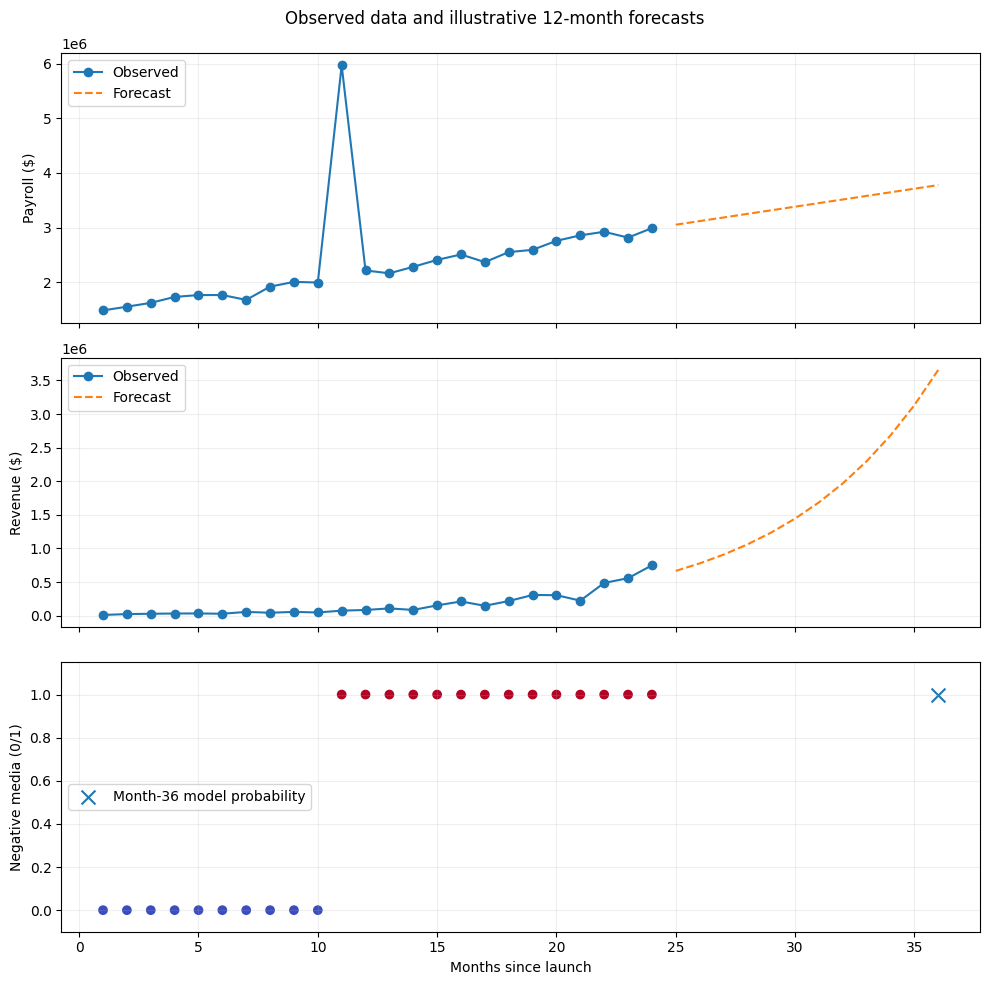

In [27]:
# Optional visual aid for your own final reflection and video.
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
axes[0].plot(df.Months_Since_Launch, df.Payroll, 'o-', label='Observed')
axes[0].plot(payroll_forecast.Months_Since_Launch,
             payroll_forecast.Predicted_Payroll, '--', label='Forecast')
axes[0].set_ylabel('Payroll ($)')
axes[0].legend(loc='upper left')
axes[1].plot(df.Months_Since_Launch, df.Revenue, 'o-', label='Observed')
axes[1].plot(revenue_forecast.Months_Since_Launch,
             revenue_forecast.Predicted_Revenue, '--', label='Forecast')
axes[1].set_ylabel('Revenue ($)')
axes[1].legend(loc='upper left')
axes[2].scatter(df.Months_Since_Launch, y_media, c=y_media, cmap='coolwarm',
                vmin=0, vmax=1)
axes[2].scatter([36], [future_negative_probability], marker='x', s=100,
                label='Month-36 model probability')
axes[2].set(xlabel='Months since launch', ylabel='Negative media (0/1)', ylim=(-.1, 1.15))
axes[2].legend(loc='center left')
for ax in axes: ax.grid(alpha=.2)
plt.suptitle('Observed data and illustrative 12-month forecasts')
plt.tight_layout()
plt.show()




Suggested word count: ~250 words



The analysis suggests that Garza Inc and Sons may continue to grow over the next 12 months, but the forecasts should be treated as directional rather than certain. The selected log-revenue regression projects revenue reaching approximately $3.66 million by month 36. This model performed better than the direct linear model on the four-month holdout when both were evaluated in dollars. Payroll is also expected to rise, with the Huber model forecasting approximately $3.78 million by month 36. Huber was selected because it produced a lower validation MAE than OLS and is less affected by the unusually high payroll observation in month 11. These figures suggest that payroll could slightly exceed revenue at the end of the forecast period, although the available data is insufficient to determine profitability because other costs and income are not included. The media model estimates a very high probability of Negative coverage in month 36, but confidence in this result is low. There are only 24 observations, the media labels are strongly associated with time, and only one scandal is recorded. The classification score on six test observations therefore should not be interpreted as proof of dependable performance. The revenue model also extrapolates a short historical trend and may overstate long-term growth. Before investing, I would request more historical financial statements, headcount and payroll details, customer and sales metrics, and information about the media events. I would then update the models and test them on additional periods. Overall, the company shows potential growth, but the evidence is too limited to support an investment decision without further due diligence.




## 2-Minute Video Presentation (1.5 marks)

Some of your (non-technical) colleagues in this venture capital firm
are in other timezones, and don't know how to program, so you need to
create a video presentation for them describing your insights.

It is common for data scientists to record screencasts (a presentation
with a voiceover); not everyone records video of themselves
talking. Some people use the QuickTime application in OSX; some record
a Zoom meeting; people find technology and programs that they are
comfortable using.

Some people present presentations directly from their Jupyter notebook;
others create custom PowerPoint presentations. 

So your choices in this section are quite open. 

- (0.5 marks) Submit a video, and ensure the video is in low resolution (SD, 480p)
  so that it is small enough to upload. Keep the time to around 2
  minutes.

- (0.6 marks) State what you believe will happen to this startup over the next 12 months:
  revenue, payroll, positive/negative media coverage. (0.6 marks)
  
- (0.4 marks) Briefly discuss any limitations or assumptions you made
  in your analysis and how they might affect your predictions. Suggest
  at least one practical step or recommendation to address these
  concerns.






## Late Assessment Submission Penalty 

Unless a Special Consideration request has been submitted and
approved, a 5% penalty (of the total possible mark of the task) will
be applied for each day a written report or presentation assessment is
not submitted, up until the 7th day (including weekends). After the
7th day, a grade of ‘0’ will be awarded even if the assessment is
submitted. The submission time for all uploaded assessments is 11:55
pm. A 1-hour grace period will be provided to students who experience
a technical concern. For any late submission of time-sensitive tasks,
such as scheduled tests/exams, performance assessments/presentations,
and/or scheduled practical assessments/labs, please apply for
[Special Consideration](https://students.mq.edu.au/study/assessment-exams/special-consideration).

For example, as this assignment is worth 15% of the entire unit, a
submission late by up to 24 hours will incur a penalty of 0.75 marks
(5% of 15 marks). A submission that is late by between 24 and 48 hours
will incur a penalty of 1.5 marks (10% of 15 marks), and so on.

## Sample Gen-AI prompts

Programming prompts:

```
Don't give me the answer directly, but help guide me to answering
this question. I will be programming in Python using the pandas and scikit-learn
libraries. If it appears that I don't know something that I would need to 
answer a question, suggest functions or classes that I should learn about. Always
add little bits of information that will guide my journey.

Here is my code so far, and the question I am trying to answer
(....)
```

If you are concerned about your grammar or language, try a prompt like this:

```
Find any grammatical mistakes, typos or other language errors in this
text. Don't make the corrections, just list for me what was wrong and
explain the problem.
```

